# P6 - Operasi Morfologi dan Komponen Terhubung (SIMUTEH v0.3-morfologi)
**Nama:** Muhammad Fahmi | **NIM:** 2330511082 | **Kelas:** TI-7B | **SEED:** 1986 | Repository: `simuteh-2330511082`

In [1]:
import sys, json, time
sys.path.append("../src")
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from utils_cv import baca, tampil
from praproses import praproses
from utils_tepi import tepi_acuan, skor_tepi, iou, mask_daun_awal, bercak_awal
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 30)
plt.rcParams["figure.dpi"] = 80
PARAM = json.load(open("../hasil/param_praproses.json"))
label = pd.read_csv("../data/sintetis/label.csv")

def muat(nama):
    img = baca(f"../data/sintetis/citra/{nama}")
    md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
    mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
    return img, md, mb

def tepi_canny(g, lo=30, hi=90, sigma=2.0):
    if sigma > 0:
        g = cv2.GaussianBlur(g, (0, 0), sigma)
    return cv2.Canny(g, lo, hi)

## Bagian 3. Operasi Morfologi pada Citra Biner
### Langkah 3.1 Lembar hitung manual (SE persegi 3 × 3, luar citra = 0)
**a)** Konektivitas 4: **4 komponen** (bercak berlubang, titik derau, piksel diagonal, garis). Konektivitas 8: **3 komponen** (piksel diagonal pada (4,4) bersentuhan diagonal dengan sudut (3,3) bercak sehingga bergabung).

**b)** Erosi: tidak ada piksel yang seluruh 9 tetangganya bernilai 1 (bercak 3 × 3 punya lubang di tengah, titik dan garis terlalu tipis) → **citra nol seluruhnya**. Opening = dilasi dari erosi = **citra nol seluruhnya**.

**c)** Closing = dilasi lalu erosi: lubang bercak **tertutup** (bercak menjadi padat 3 × 3) dan piksel diagonal (4,4) terhubung ke garis di baris 8 lewat jembatan (4,4)-(5,4)-(6,4): celah dua piksel **tertutup**, sehingga bercak, piksel diagonal, dan garis bergabung menjadi satu komponen (komponen menjadi 2: gabungan itu dan titik derau).

**d)** Closing lalu opening: hanya **bercak padat 3 × 3** (baris 2-4, kolom 2-4, indeks dari 1) yang tersisa; titik derau, jembatan, dan garis terhapus. 1 komponen.

Verifikasi matriks lengkap dengan kode pada sel berikut.

In [2]:
# Verifikasi lembar hitung 3.1 (piksel di luar citra = 0 -> BORDER_CONSTANT)
B = np.array([[0,0,0,0,0,0,0,0,0],[0,1,1,1,0,0,0,0,0],[0,1,0,1,0,0,0,1,0],[0,1,1,1,0,0,0,0,0],
              [0,0,0,0,1,0,0,0,0],[0,0,0,0,0,0,0,0,0],[0,0,0,0,0,0,0,0,0],[0,1,1,1,1,1,1,0,0],
              [0,0,0,0,0,0,0,0,0]], np.uint8)
S = np.ones((3, 3), np.uint8)
er = lambda x: cv2.erode(x, S, borderType=cv2.BORDER_CONSTANT, borderValue=0)
di = lambda x: cv2.dilate(x, S, borderType=cv2.BORDER_CONSTANT, borderValue=0)
op = lambda x: di(er(x)); cl = lambda x: er(di(x))
for k in (4, 8):
    print(f"a) konektivitas {k}: {cv2.connectedComponents(B, connectivity=k)[0] - 1} komponen")
for nm, M in [("b) erosi", er(B)), ("b) opening", op(B)), ("c) closing", cl(B)), ("d) closing lalu opening", op(cl(B)))]:
    print(nm); print(M)
print("komponen (8) setelah closing:", cv2.connectedComponents(cl(B), connectivity=8)[0] - 1,
      "| setelah closing lalu opening:", cv2.connectedComponents(op(cl(B)), connectivity=8)[0] - 1)

a) konektivitas 4: 4 komponen
a) konektivitas 8: 3 komponen
b) erosi
[[0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]]
b) opening
[[0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]]
c) closing
[[0 0 0 0 0 0 0 0 0]
 [0 1 1 1 0 0 0 0 0]
 [0 1 1 1 0 0 0 1 0]
 [0 1 1 1 0 0 0 0 0]
 [0 0 0 0 1 0 0 0 0]
 [0 0 0 0 1 0 0 0 0]
 [0 0 0 0 1 0 0 0 0]
 [0 1 1 1 1 1 1 0 0]
 [0 0 0 0 0 0 0 0 0]]
d) closing lalu opening
[[0 0 0 0 0 0 0 0 0]
 [0 1 1 1 0 0 0 0 0]
 [0 1 1 1 0 0 0 0 0]
 [0 1 1 1 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]]
komponen (8) setelah closing: 2 | setelah closing lalu opening: 1


### Langkah 3.2 Citra biner awal

         citra  IoU daun awal  komponen bercak awal  komponen acuan IoU bercak awal
0  teh_041.png          0.992                   222               9           0.715
1  teh_021.png          0.996                   195               3            0.28
2  teh_011.png          0.998                   103               0               -


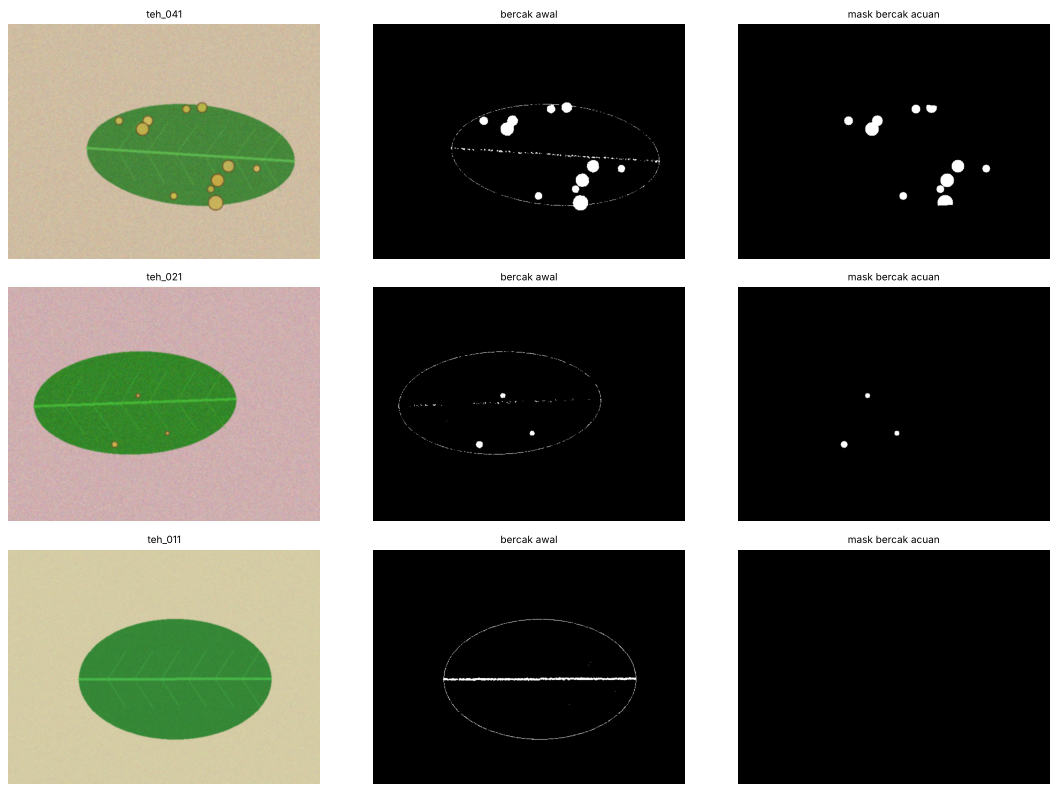

In [3]:
def jumlah_komponen(m, konek=8):
    return cv2.connectedComponents((m > 0).astype(np.uint8), connectivity=konek)[0] - 1

baris, panel, judul = [], [], []
for nama in ["teh_041.png", "teh_021.png", "teh_011.png"]:       # berat, ringan, sehat
    img, md, mb = muat(nama)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    b0 = bercak_awal(pra_, m_daun, kanal=2, k=4.0)
    baris.append([nama, round(iou(m_daun, md), 3), jumlah_komponen(b0), jumlah_komponen(mb),
                  round(iou(b0, mb), 3) if mb.any() else "-"])
    panel += [pra_, b0, mb]; judul += [nama[:7], "bercak awal", "mask bercak acuan"]
print(pd.DataFrame(baris, columns=["citra", "IoU daun awal", "komponen bercak awal", "komponen acuan", "IoU bercak awal"]))
tampil(panel, judul, baris=3, ukuran=(14, 10))
plt.savefig("../hasil/p6_bercak_awal.png", bbox_inches="tight"); plt.show()

### Langkah 3.3 Enam operasi (SE elips 5 × 5)

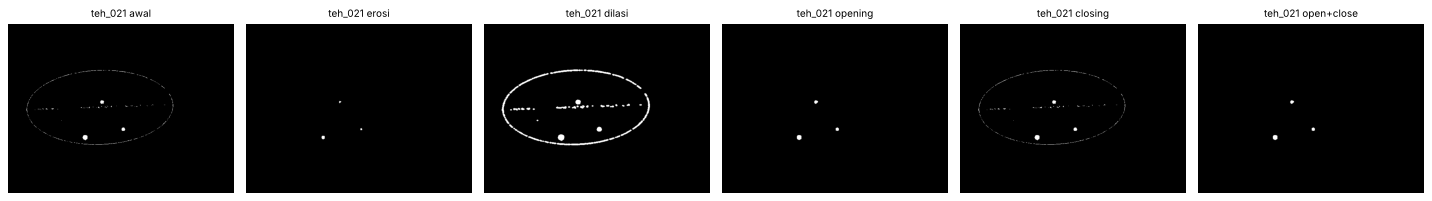

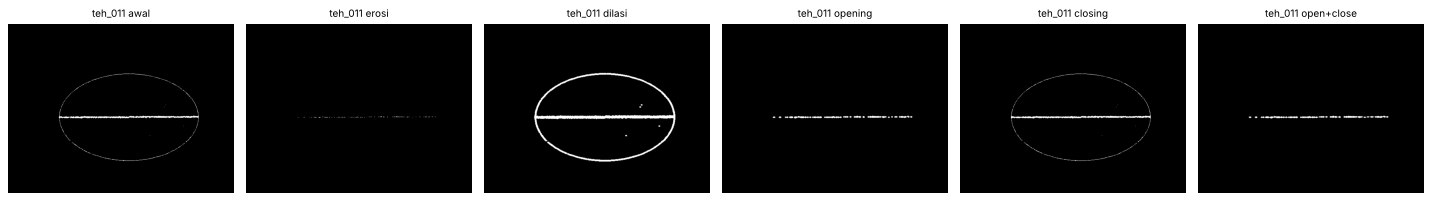

          citra     operasi  komponen  piksel    IoU
0   teh_021.png        awal       195    1069   0.28
1   teh_021.png       erosi         3     128  0.412
2   teh_021.png      dilasi        42    5823  0.053
3   teh_021.png     opening         3     305  0.895
4   teh_021.png     closing       182    1107  0.272
5   teh_021.png  open+close         3     305  0.895
6   teh_011.png        awal       103    2604      -
7   teh_011.png       erosi        56     172      -
8   teh_011.png      dilasi         5    8330      -
9   teh_011.png     opening        20    1299      -
10  teh_011.png     closing        92    2656      -
11  teh_011.png  open+close         6    1343      -


In [4]:
SE = lambda k, bentuk=cv2.MORPH_ELLIPSE: cv2.getStructuringElement(bentuk, (k, k))

def operasi(b, se):
    return {"awal": b,
            "erosi": cv2.erode(b, se),
            "dilasi": cv2.dilate(b, se),
            "opening": cv2.morphologyEx(b, cv2.MORPH_OPEN, se),
            "closing": cv2.morphologyEx(b, cv2.MORPH_CLOSE, se),
            "open+close": cv2.morphologyEx(cv2.morphologyEx(b, cv2.MORPH_OPEN, se), cv2.MORPH_CLOSE, se)}

baris = []
for nama in ["teh_021.png", "teh_011.png"]:
    img, md, mb = muat(nama)
    pra_ = praproses(img, PARAM)
    b0 = bercak_awal(pra_, mask_daun_awal(pra_))
    hasil = operasi(b0, SE(5))
    for nm, m in hasil.items():
        baris.append([nama, nm, jumlah_komponen(m), int((m > 0).sum()),
                      round(iou(m, mb), 3) if mb.any() else "-"])
    tampil(list(hasil.values()), [f"{nama[:7]} {k}" for k in hasil.keys()], ukuran=(18, 3))
    plt.savefig(f"../hasil/p6_operasi_{nama[:7]}.png", bbox_inches="tight"); plt.show()
print(pd.DataFrame(baris, columns=["citra", "operasi", "komponen", "piksel", "IoU"]))

### Langkah 3.4 Eksperimen k, bentuk, dan ukuran SE (Tabel 9)

In [5]:
bentuk = {"persegi": cv2.MORPH_RECT, "elips": cv2.MORPH_ELLIPSE, "silang": cv2.MORPH_CROSS}
baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    n_acuan = jumlah_komponen(mb)
    for k in [3, 4, 6]:
        b0 = bercak_awal(pra_, m_daun, k=k)
        for nb, kb in bentuk.items():
            for uk in [3, 5, 7]:
                se = SE(uk, kb)
                m = cv2.morphologyEx(cv2.morphologyEx(b0, cv2.MORPH_OPEN, se), cv2.MORPH_CLOSE, se)
                baris.append([d.kelas, k, nb, uk, abs(jumlah_komponen(m) - n_acuan),
                              iou(m, mb) if mb.any() else np.nan])
eks = pd.DataFrame(baris, columns=["kelas", "k", "bentuk", "ukuran", "galat_jumlah", "IoU"])
print(eks.pivot_table(index=["k", "bentuk", "ukuran"], columns="kelas", values=["galat_jumlah", "IoU"]).round(2))
eks.to_csv("../hasil/p6_eksperimen_se.csv", index=False)
print("\nTABEL 9 (k = 4)")
e4 = eks[eks.k == 4]
t9 = pd.DataFrame({
    "IoU berat": e4[e4.kelas == "berat"].groupby(["bentuk", "ukuran"]).IoU.mean(),
    "IoU ringan": e4[e4.kelas == "ringan"].groupby(["bentuk", "ukuran"]).IoU.mean(),
    "Galat jumlah berat": e4[e4.kelas == "berat"].groupby(["bentuk", "ukuran"]).galat_jumlah.mean(),
    "Galat jumlah ringan": e4[e4.kelas == "ringan"].groupby(["bentuk", "ukuran"]).galat_jumlah.mean(),
    "Galat jumlah sehat": e4[e4.kelas == "sehat"].groupby(["bentuk", "ukuran"]).galat_jumlah.mean()}).round(2)
print(t9); t9.to_csv("../hasil/p6_tabel9.csv")
print("\nRINGKAS per k (bentuk elips, ukuran 5):")
print(eks[(eks.bentuk == "elips") & (eks.ukuran == 5)].groupby(["k", "kelas"])[["galat_jumlah", "IoU"]].mean().round(2).unstack())

                   IoU        galat_jumlah              
kelas            berat ringan        berat ringan  sehat
k bentuk  ukuran                                        
3 elips   3       0.72   0.41        17.55  31.90  14.70
          5       0.79   0.61         2.35   2.45   3.75
          7       0.83   0.72         0.90   0.95   1.80
  persegi 3       0.74   0.47         8.80   9.35   7.00
          5       0.81   0.69         1.20   1.50   1.70
          7       0.82   0.72         0.50   0.30   0.00
  silang  3       0.72   0.41        17.55  31.90  14.70
          5       0.78   0.59         5.40   4.60   6.10
          7       0.83   0.67         1.70   2.80   2.65
4 elips   3       0.78   0.58        10.05  22.45  10.30
          5       0.81   0.68         1.35   1.75   1.20
          7       0.82   0.74         0.40   0.25   0.20
  persegi 3       0.79   0.63         3.25   4.50   4.85
          5       0.81   0.72         1.10   0.80   1.70
          7       0.80   0.70  

### Langkah 3.5 Gradien morfologi vs Canny

In [6]:
baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    grad = cv2.morphologyEx(m_daun, cv2.MORPH_GRADIENT, SE(3))          # dilasi - erosi
    canny = tepi_canny(cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY))
    ad = tepi_acuan(md)
    baris.append([d.kondisi_cahaya, skor_tepi(grad, ad)[2], skor_tepi(canny, ad)[2]])
print(pd.DataFrame(baris, columns=["kondisi", "F1 gradien morfologi", "F1 Canny"]).groupby("kondisi").mean().round(3))

                F1 gradien morfologi  F1 Canny
kondisi                                       
bayangan                       0.897     0.894
gelap                          0.945     0.922
kontras_rendah                 0.384     0.000
normal                         0.990     0.908
terang                         0.984     0.931


### Langkah 3.6 (Kerjakan sendiri) Panel structuring element

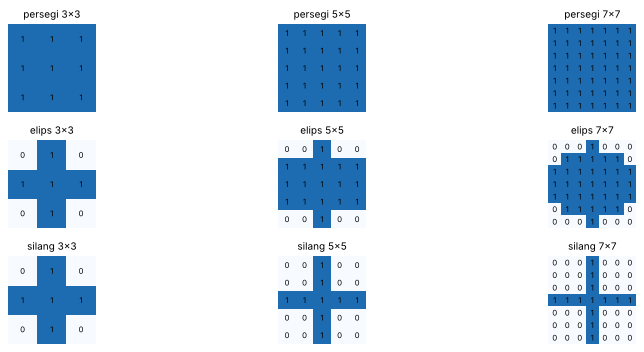

elips 3x3 == silang 3x3 ? True
[[0 0 1 0 0]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [0 0 1 0 0]]


In [7]:
# Langkah 3.6 (kerjakan sendiri): panel structuring element
plt.figure(figsize=(12, 4.5))
i = 1
for nb, kb in bentuk.items():
    for uk in [3, 5, 7]:
        plt.subplot(3, 3, i); se = cv2.getStructuringElement(kb, (uk, uk))
        plt.imshow(se, cmap="Blues", vmin=0, vmax=1.3); plt.title(f"{nb} {uk}x{uk}", fontsize=9)
        for (yy, xx), v in np.ndenumerate(se):
            plt.text(xx, yy, int(v), ha="center", va="center", fontsize=7)
        plt.axis("off"); i += 1
plt.tight_layout(); plt.savefig("../hasil/p6_panel_se.png", bbox_inches="tight"); plt.show()
print("elips 3x3 == silang 3x3 ?", np.array_equal(cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3)),
                                                   cv2.getStructuringElement(cv2.MORPH_CROSS, (3, 3))))
print(cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5)))

## Bagian 4. Komponen Terhubung dan Pengukuran Bercak
### Langkah 4.1 Lembar hitung manual (1 piksel = 0,4375 mm)
| Objek | Luas (px) | Luas (mm²) | Keliling | Kebulatan 4πA/K² | Rasio aspek |
|---|---|---|---|---|---|
| Bercak 3 × 3 (hasil 3.1d) | 9 | 9 × 0,1914 = **1,72** | 12 | 4π·9/144 = **0,785** | 3/3 = **1,0** |
| Garis 1 × 6 | 6 | 6 × 0,1914 = **1,15** | 14 | 4π·6/196 = **0,385** | 6/1 = **6,0** |

**c)** Aturan sederhana: komponen dianggap bercak bila **kebulatan ≥ 0,5 dan rasio aspek ≤ 1,8**; garis (0,385 dan 6,0) ditolak, bercak 3 × 3 (0,785 dan 1,0) lolos.

In [8]:
# Verifikasi lembar hitung 4.1
MM = 0.4375
bers = op(cl(B))                     # hasil 3.1 d)
garis = np.zeros_like(B); garis[7, 1:7] = 1
def ukur_kecil(m):
    A = int(m.sum())
    ys, xs = np.where(m > 0); h, w = np.ptp(ys) + 1, np.ptp(xs) + 1
    # keliling = jumlah sisi piksel yang berbatasan dengan latar
    p = np.pad(m, 1); kel = sum(int(((p[1:-1, 1:-1] == 1) & (np.roll(p, s, a)[1:-1, 1:-1] == 0)).sum()) for a in (0, 1) for s in (1, -1))
    return A, round(A * MM ** 2, 3), kel, round(4 * np.pi * A / kel ** 2, 3), round(max(h, w) / min(h, w), 2)
print("kolom: luas_px, luas_mm2, keliling, kebulatan, rasio_aspek")
print("bercak 3x3 :", ukur_kecil(bers)); print("garis 1x6  :", ukur_kecil(garis))

kolom: luas_px, luas_mm2, keliling, kebulatan, rasio_aspek
bercak 3x3 : (9, 1.723, 12, 0.785, np.float64(1.0))
garis 1x6  : (6, 1.148, 14, 0.385, np.float64(6.0))


### Langkah 4.2 Label dan ukur (Tabel 10)

konektivitas 4: 9 komponen
konektivitas 8: 9 komponen
   label  luas_px  luas_mm2  keliling_px  kebulatan  rasio_aspek   cx   cy
0      1      362     69.29         67.9       0.99         1.05  397  169
1      2      235     44.98         56.3       0.93         1.06  364  172
2      3      919    175.90        125.4       0.73         1.61  279  207
3      4      231     44.21         54.6       0.97         1.00  227  197
4      5      488     93.41         81.4       0.93         1.09  450  289
5      6      179     34.26         48.6       0.95         1.00  509  295
6      7      783    149.87        128.6       0.60         1.56  425  323
7      8      186     35.60         49.2       0.97         1.07  339  350
8      9      764    146.23        101.8       0.93         1.00  425  365


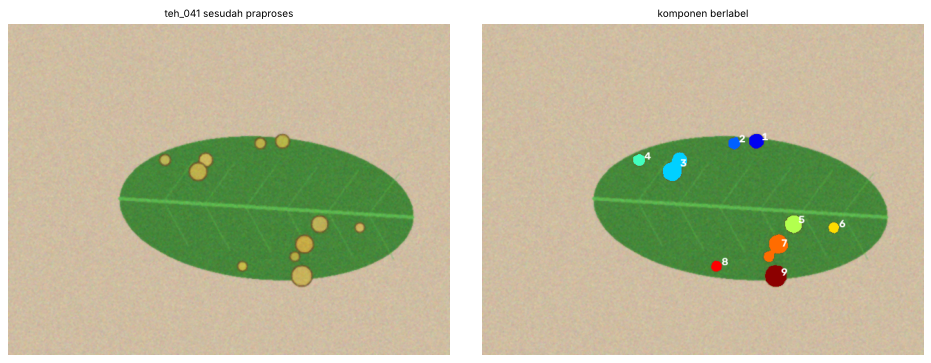

In [9]:
MM_PER_PX = 0.4375          # dari lembar hitung P2: Z = 200 mm, lebar kerja 640 px

def ukur_komponen(m, konek=8):
    n, lbl, st, cen = cv2.connectedComponentsWithStats((m > 0).astype(np.uint8), connectivity=konek)
    baris = []
    for i in range(1, n):
        kontur, _ = cv2.findContours((lbl == i).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        A = int(st[i, cv2.CC_STAT_AREA])
        keliling = cv2.arcLength(kontur[0], True)
        kebulatan = 0.0 if keliling == 0 else 4 * np.pi * A / keliling ** 2
        w, h = cv2.minAreaRect(kontur[0])[1]
        rasio = max(w, h) / max(min(w, h), 1)
        baris.append([i, A, round(A * MM_PER_PX ** 2, 2), round(keliling, 1), round(kebulatan, 2),
                      round(rasio, 2), int(cen[i][0]), int(cen[i][1])])
    kolom = ["label", "luas_px", "luas_mm2", "keliling_px", "kebulatan", "rasio_aspek", "cx", "cy"]
    return pd.DataFrame(baris, columns=kolom), lbl

img, md, mb = muat("teh_041.png")
pra_ = praproses(img, PARAM)
m_daun = mask_daun_awal(pra_)
bersih = cv2.morphologyEx(cv2.morphologyEx(bercak_awal(pra_, m_daun), cv2.MORPH_OPEN, SE(5)), cv2.MORPH_CLOSE, SE(5))
for konek in [4, 8]:
    print(f"konektivitas {konek}: {jumlah_komponen(bersih, konek)} komponen")
tabel_kom, lbl = ukur_komponen(bersih)
print(tabel_kom)
tabel_kom.to_csv("../hasil/p6_tabel10_teh041.csv", index=False)
warna = cv2.applyColorMap((lbl * (255 // max(lbl.max(), 1))).astype(np.uint8), cv2.COLORMAP_JET)
warna[lbl == 0] = pra_[lbl == 0]
for _, r in tabel_kom.iterrows():
    cv2.putText(warna, str(int(r.label)), (int(r.cx) + 8, int(r.cy)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 2)
tampil([pra_, warna], ["teh_041 sesudah praproses", "komponen berlabel"], ukuran=(12, 4.5))
plt.savefig("../hasil/p6_berlabel_teh041.png", bbox_inches="tight"); plt.show()

### Langkah 4.3 Penyaringan bercak palsu (Tabel 11)

In [10]:
def saring(m, luas_min=20, bulat_min=0.5, rasio_maks=1.8):
    tabel_k, lbl = ukur_komponen(m)
    lolos = tabel_k[(tabel_k.luas_px >= luas_min) & (tabel_k.kebulatan >= bulat_min) & (tabel_k.rasio_aspek <= rasio_maks)]
    return (np.isin(lbl, lolos.label.values) * 255).astype(np.uint8), lolos

aturan = {"tanpa saring": (0, 0, 99), "luas >= 20": (20, 0, 99),
          "luas + kebulatan": (20, 0.5, 99), "luas + kebulatan + rasio": (20, 0.5, 1.8)}
baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    bersih = cv2.morphologyEx(cv2.morphologyEx(bercak_awal(pra_, m_daun), cv2.MORPH_OPEN, SE(5)), cv2.MORPH_CLOSE, SE(5))
    for nm, (a, b, r) in aturan.items():
        f, _ = saring(bersih, a, b, r)
        baris.append([d.kelas, nm, jumlah_komponen(f), jumlah_komponen(mb)])
uji = pd.DataFrame(baris, columns=["kelas", "aturan", "jumlah", "acuan"])
uji["galat"] = (uji.jumlah - uji.acuan).abs()
t11 = uji.pivot_table(index="aturan", columns="kelas", values="galat").round(2)
print(t11)
print("Daun sehat yang masih memiliki bercak palsu:")
palsu = uji[uji.kelas == "sehat"].assign(palsu=lambda t: t.jumlah > 0).groupby("aturan").palsu.sum()
print(palsu)
t11["sehat_palsu"] = palsu; t11.to_csv("../hasil/p6_tabel11.csv")

kelas                     berat  ringan  sehat
aturan                                        
luas + kebulatan           0.95    0.65   0.45
luas + kebulatan + rasio   0.60    0.35   0.40
luas >= 20                 0.95    1.35   1.05
tanpa saring               1.35    1.75   1.20
Daun sehat yang masih memiliki bercak palsu:
aturan
luas + kebulatan            4
luas + kebulatan + rasio    4
luas >= 20                  6
tanpa saring                6
Name: palsu, dtype: int64


### Langkah 4.4 (Kerjakan sendiri) Dasar ambang penyaringan

komponen total: 271 | benar: 184 | palsu: 87
benar                False    True 
luas_px     count    87.00   184.00
            mean    153.71   374.59
            std     359.71   301.84
            min      17.00    17.00
            25%      22.00   179.75
            50%      48.00   280.50
            75%     101.00   496.25
            max    2185.00  2189.00
kebulatan   count    87.00   184.00
            mean      0.72     0.90
            std       0.40     0.11
            min       0.03     0.41
            25%       0.38     0.88
            50%       0.76     0.93
            75%       1.13     0.97
            max       1.15     1.15
rasio_aspek count    87.00   184.00
            mean      5.28     1.13
            std       9.23     0.24
            min       1.00     1.00
            25%       1.25     1.00
            50%       2.25     1.05
            75%       4.51     1.11
            max      64.54     2.62


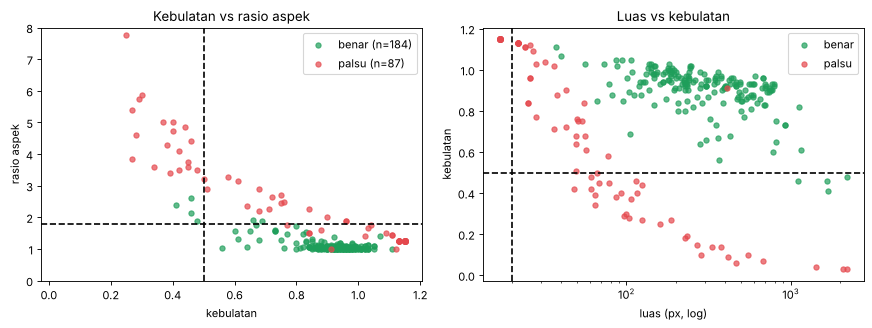

palsu menurut kondisi:
kondisi
bayangan     1
normal      33
terang      53
dtype: int64
benar yang tersingkir oleh aturan final: 7
palsu yang lolos aturan final: 19


In [11]:
# Langkah 4.4 (kerjakan sendiri): komponen benar vs palsu pada 60 citra
baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    bersih = cv2.morphologyEx(cv2.morphologyEx(bercak_awal(pra_, mask_daun_awal(pra_)), cv2.MORPH_OPEN, SE(5)), cv2.MORPH_CLOSE, SE(5))
    tk, lb = ukur_komponen(bersih)
    for _, r in tk.iterrows():
        frac = (mb[lb == r.label] > 0).mean()
        baris.append([d.nama_file, d.kelas, d.kondisi_cahaya, r.luas_px, r.kebulatan, r.rasio_aspek, frac > 0.5])
kom = pd.DataFrame(baris, columns=["nama", "kelas", "kondisi", "luas_px", "kebulatan", "rasio_aspek", "benar"])
print("komponen total:", len(kom), "| benar:", int(kom.benar.sum()), "| palsu:", int((~kom.benar).sum()))
print(kom.groupby("benar")[["luas_px", "kebulatan", "rasio_aspek"]].describe().T.round(2))
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for v, c, nm in [(True, "#1E9E5A", "benar"), (False, "#E5484D", "palsu")]:
    s = kom[kom.benar == v]
    ax[0].scatter(s.kebulatan, s.rasio_aspek, c=c, label=f"{nm} (n={len(s)})", alpha=.7, s=22)
    ax[1].scatter(s.luas_px, s.kebulatan, c=c, label=nm, alpha=.7, s=22)
ax[0].axvline(0.5, ls="--", c="k"); ax[0].axhline(1.8, ls="--", c="k")
ax[0].set_xlabel("kebulatan"); ax[0].set_ylabel("rasio aspek"); ax[0].set_ylim(0, 8); ax[0].legend(); ax[0].set_title("Kebulatan vs rasio aspek")
ax[1].axvline(20, ls="--", c="k"); ax[1].axhline(0.5, ls="--", c="k")
ax[1].set_xscale("log"); ax[1].set_xlabel("luas (px, log)"); ax[1].set_ylabel("kebulatan"); ax[1].set_title("Luas vs kebulatan"); ax[1].legend()
plt.tight_layout(); plt.savefig("../hasil/p6_sebar_benar_palsu.png", bbox_inches="tight"); plt.show()
kom.to_csv("../hasil/p6_komponen_benar_palsu.csv", index=False)
print("palsu menurut kondisi:"); print(kom[~kom.benar].groupby("kondisi").size())
print("benar yang tersingkir oleh aturan final:", int(((kom.benar) & ((kom.luas_px < 20) | (kom.kebulatan < .5) | (kom.rasio_aspek > 1.8))).sum()))
print("palsu yang lolos aturan final:", int(((~kom.benar) & (kom.luas_px >= 20) & (kom.kebulatan >= .5) & (kom.rasio_aspek <= 1.8)).sum()))

### Bukti untuk P4.4 (luas total teh_041 vs acuan)

In [12]:
# P4.4: luas total bercak teh_041 hasil vs mask acuan
img, md, mb = muat("teh_041.png"); pra_ = praproses(img, PARAM)
m_daun = mask_daun_awal(pra_)
b0 = bercak_awal(pra_, m_daun)
bersih = cv2.morphologyEx(cv2.morphologyEx(b0, cv2.MORPH_OPEN, SE(5)), cv2.MORPH_CLOSE, SE(5))
fin, _ = saring(bersih)
print("luas acuan (px)        :", int((mb > 0).sum()))
for nm, m in [("bercak awal", b0), ("sesudah open+close", bersih), ("sesudah saring (final)", fin)]:
    print(f"{nm:24s}: {int((m>0).sum())} px  selisih {100*((m>0).sum()-(mb>0).sum())/(mb>0).sum():+.1f}%  IoU {iou(m, mb):.3f}")
# nilai kanal R: inti bercak, cincin cokelat, daun, pada citra praproses
inti = (cv2.erode(mb, np.ones((7, 7), np.uint8)) > 0)
cincin = (mb > 0) & ~inti
daun = (md > 0) & (mb == 0)
R = pra_[:, :, 2].astype(float)
print("rerata R: inti bercak %.0f | cincin tepi %.0f | daun sehat %.0f | ambang median+4MAD %.0f" % (
    R[inti].mean(), R[cincin].mean(), R[daun].mean(), np.median(R[m_daun > 0]) + 4 * 1.4826 * np.median(np.abs(R[m_daun > 0] - np.median(R[m_daun > 0])))))
print("luas cincin tepi dalam acuan: %.1f%% dari luas bercak acuan" % (100 * cincin.sum() / (mb > 0).sum()))
print("IoU daun awal vs acuan: %.3f ; luas daun awal / acuan = %.3f" % (iou(m_daun, md), (m_daun > 0).sum() / (md > 0).sum()))
# sanding tanpa praproses (tanpa median) untuk melihat pengaruh penapis
for nm, im in [("mentah", img), ("praproses", pra_)]:
    mdn = mask_daun_awal(im); bb = bercak_awal(im, mdn)
    print(f"{nm:10s} bercak awal: {(bb>0).sum()} px")

luas acuan (px)        : 4031
bercak awal             : 5167 px  selisih +28.2%  IoU 0.715
sesudah open+close      : 4147 px  selisih +2.9%  IoU 0.873
sesudah saring (final)  : 4147 px  selisih +2.9%  IoU 0.873
rerata R: inti bercak 193 | cincin tepi 143 | daun sehat 71 | ambang median+4MAD 95
luas cincin tepi dalam acuan: 55.8% dari luas bercak acuan
IoU daun awal vs acuan: 0.992 ; luas daun awal / acuan = 1.001
mentah     bercak awal: 3909 px
praproses  bercak awal: 5167 px


## Bagian 5. Integrasi: Modul `src/bercak.py`
Modul dibuat dari kerangka (ketujuh TODO selesai) di `src/bercak.py`; evaluasi memakai Kode 5.2.

Galat absolut rerata persen bercak: 0.335
Korelasi persen prediksi vs acuan : 0.967
Akurasi kelas : 0.983
prediksi       Bercak Berat  Bercak Ringan  Sehat
acuan                                            
Bercak Berat             20              0      0
Bercak Ringan             0             19      1
Sehat                     0              0     20
kondisi
bayangan          0.92
gelap             1.00
kontras_rendah    1.00
normal            1.00
terang            1.00
Name: benar, dtype: float64


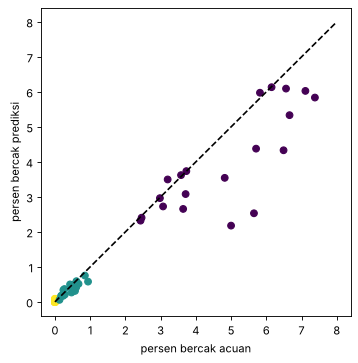

In [13]:
import importlib, bercak
importlib.reload(bercak)
PB = {}                                   # ubah parameter sesuai temuan Anda
bercak.simpan_param(PB)
baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    h = bercak.analisis_daun(praproses(img, PARAM), PB)
    baris.append([d.nama_file, d.kelas, d.kondisi_cahaya, d.persen_bercak, h["persen_bercak"],
                  jumlah_komponen(mb), h["jumlah_bercak"], h["kelas"]])
ev = pd.DataFrame(baris, columns=["nama", "kelas", "kondisi", "persen_acuan", "persen_prediksi",
                                  "jumlah_acuan", "jumlah_prediksi", "kelas_prediksi"])
ev["kelas_acuan"] = ev.kelas.map({"sehat": "Sehat", "ringan": "Bercak Ringan", "berat": "Bercak Berat"})
ev.to_csv("../hasil/p6_evaluasi_bercak.csv", index=False)
print("Galat absolut rerata persen bercak:", (ev.persen_prediksi - ev.persen_acuan).abs().mean().round(3))
print("Korelasi persen prediksi vs acuan :", ev[["persen_prediksi", "persen_acuan"]].corr().iloc[0, 1].round(3))
print("Akurasi kelas :", (ev.kelas_prediksi == ev.kelas_acuan).mean().round(3))
print(pd.crosstab(ev.kelas_acuan, ev.kelas_prediksi, rownames=["acuan"], colnames=["prediksi"]))
print(ev.assign(benar=ev.kelas_prediksi == ev.kelas_acuan).groupby("kondisi").benar.mean().round(2))
plt.figure(figsize=(5, 5))
plt.scatter(ev.persen_acuan, ev.persen_prediksi, c=ev.kelas.astype("category").cat.codes)
plt.plot([0, 8], [0, 8], "k--"); plt.xlabel("persen bercak acuan"); plt.ylabel("persen bercak prediksi")
plt.savefig("../hasil/p6_sebar_persen.png", bbox_inches="tight"); plt.show()

In [14]:
# Ukuran tambahan untuk Tabel 12 dan analisis
print("daun sehat dinilai berbercak :", int(((ev.kelas_acuan == "Sehat") & (ev.kelas_prediksi != "Sehat")).sum()))
print("daun berbercak dinilai sehat :", int(((ev.kelas_acuan != "Sehat") & (ev.kelas_prediksi == "Sehat")).sum()))
print("galat jumlah bercak rerata   :", (ev.jumlah_prediksi - ev.jumlah_jumlah_acuan if False else (ev.jumlah_prediksi - ev.jumlah_acuan).abs()).mean().round(3))
print("galat persen per kelas:"); print((ev.persen_prediksi - ev.persen_acuan).abs().groupby(ev.kelas).mean().round(3))
print("bias (prediksi - acuan) per kelas:"); print((ev.persen_prediksi - ev.persen_acuan).groupby(ev.kelas).mean().round(3))
akur = ev.assign(benar=ev.kelas_prediksi == ev.kelas_acuan).groupby("kondisi").benar.mean()
print("kondisi akurasi terendah:", akur.idxmin(), akur.min().round(3))
salah = ev[ev.kelas_prediksi != ev.kelas_acuan]; print(salah[["nama", "kelas_acuan", "kelas_prediksi", "kondisi", "persen_acuan", "persen_prediksi", "jumlah_acuan", "jumlah_prediksi"]])

daun sehat dinilai berbercak : 0
daun berbercak dinilai sehat : 1
galat jumlah bercak rerata   : 0.45
galat persen per kelas:
kelas
berat     0.889
ringan    0.101
sehat     0.015
dtype: float64
bias (prediksi - acuan) per kelas:
kelas
berat    -0.839
ringan   -0.073
sehat     0.015
dtype: float64
kondisi akurasi terendah: bayangan 0.917
           nama    kelas_acuan kelas_prediksi   kondisi  persen_acuan  persen_prediksi  jumlah_acuan  jumlah_prediksi
24  teh_025.png  Bercak Ringan          Sehat  bayangan          0.13            0.058             1                1


### Langkah 5.3 (Kerjakan sendiri) Analisis kesalahan

jumlah citra salah kelas: 1


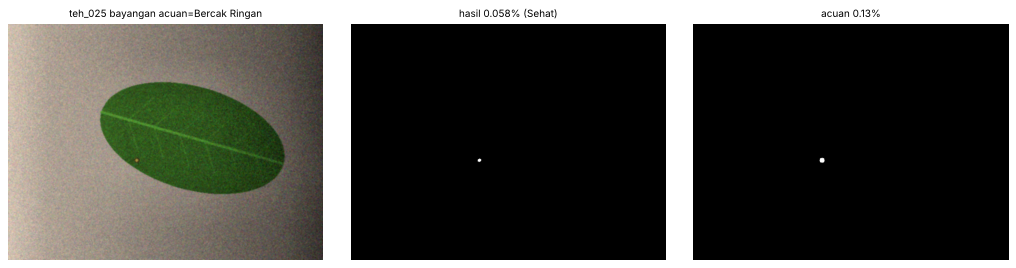

In [15]:
# Langkah 5.3 (kerjakan sendiri): analisis kesalahan - citra salah kelas
salah = ev[ev.kelas_prediksi != ev.kelas_acuan]
print("jumlah citra salah kelas:", len(salah))
if len(salah):
    daftar, judul = [], []
    for _, r in salah.iterrows():
        img, md, mb = muat(r.nama)
        h = bercak.analisis_daun(praproses(img, PARAM), PB)
        daftar += [praproses(img, PARAM), h["mask_bercak"], mb]
        judul += [f"{r.nama[:7]} {r.kondisi} acuan={r.kelas_acuan}", f"hasil {r.persen_prediksi}% ({r.kelas_prediksi})", f"acuan {r.persen_acuan}%"]
    tampil(daftar, judul, baris=len(salah), ukuran=(13, 3.3 * len(salah)))
    plt.savefig("../hasil/p6_citra_salah.png", bbox_inches="tight"); plt.show()

### Eksperimen pendukung: variasi parameter, pemilihan batas dari data latih, sumber galat, uji bentuk tak beraturan, waktu proses

In [16]:
# ---- Eksperimen pendukung Bagian 5 ----
cache = {n: (muat(n), ) for n in label.nama_file}
PRA = {n: praproses(cache[n][0][0], PARAM) for n in label.nama_file}

def evaluasi(pb):
    r = []
    for _, d in label.iterrows():
        h = bercak.analisis_daun(PRA[d.nama_file], pb)
        r.append([d.nama_file, d.kelas, d.persen_bercak, h["persen_bercak"], h["kelas"]])
    e = pd.DataFrame(r, columns=["nama", "kelas", "acuan", "pred", "kelas_pred"])
    e["ka"] = e.kelas.map({"sehat": "Sehat", "ringan": "Bercak Ringan", "berat": "Bercak Berat"})
    return e

# (1) variasi parameter pada pipeline lengkap
varian = {"bawaan (k4, elips5, filter penuh)": {}, "k=3": {"k": 3.0}, "k=6": {"k": 6.0},
          "SE elips 3": {"se_open": 3, "se_close": 3}, "SE elips 7": {"se_open": 7, "se_close": 7},
          "tanpa opening": {"se_open": 0}, "tanpa closing": {"se_close": 0},
          "tanpa filter bentuk": {"bulat_min": 0.0, "rasio_maks": 99}, "tanpa filter luas": {"luas_min": 0},
          "persegi 5": {"se_bentuk": "persegi"}}
baris = []
for nm, pb in varian.items():
    e = evaluasi(pb)
    baris.append([nm, round((e.pred - e.acuan).abs().mean(), 3), round(e.pred.corr(e.acuan), 3), round((e.kelas_pred == e.ka).mean(), 3),
                  int(((e.ka == "Sehat") & (e.kelas_pred != "Sehat")).sum()), int(((e.ka != "Sehat") & (e.kelas_pred == "Sehat")).sum())])
var = pd.DataFrame(baris, columns=["varian", "galat_abs_persen", "korelasi", "akurasi", "sehat_dinilai_bercak", "bercak_dinilai_sehat"])
print(var.to_string(index=False)); var.to_csv("../hasil/p6_varian_parameter.csv", index=False)

# (2) sebaran persen prediksi per kelas dan batas kelas
e0 = evaluasi({})
print(e0.groupby("kelas").pred.describe().round(3))
print("acuan ringan min/maks:", label[label.kelas == "ringan"].persen_bercak.min(), label[label.kelas == "ringan"].persen_bercak.max(),
      "| acuan berat min:", label[label.kelas == "berat"].persen_bercak.min())

# (3) batas kelas dipilih HANYA dari data latih (50%), diuji pada data uji (50%), 200 pembagian acak berstrata
rng = np.random.default_rng(1986)
def cari_batas(t):
    """Cari (batas_ringan, batas_berat) dengan akurasi latih tertinggi; bila seri, ambil titik tengah plateau."""
    kandidat = []
    for a in np.arange(0.02, 0.30, 0.01):
        for b in np.arange(1.0, 2.6, 0.1):
            kp = np.where(t.pred >= b, "Bercak Berat", np.where(t.pred >= a, "Bercak Ringan", "Sehat"))
            kandidat.append(((kp == t.ka).mean(), a, b))
    kandidat = np.array(kandidat); m = kandidat[:, 0].max()
    top = kandidat[kandidat[:, 0] >= m - 1e-12]
    return m, (top[:, 1].mean(), top[:, 2].mean())
hasil_cv = []
for _ in range(60):
    tr_idx = np.concatenate([rng.permutation(np.where(e0.kelas == k)[0])[:10] for k in ["sehat", "ringan", "berat"]])
    tr = e0.iloc[tr_idx]; te = e0.drop(e0.index[tr_idx])
    ak_tr, (a, b) = cari_batas(tr)
    kp = np.where(te.pred >= b, "Bercak Berat", np.where(te.pred >= a, "Bercak Ringan", "Sehat"))
    hasil_cv.append([ak_tr, (kp == te.ka).mean(), a, b])
cv_ = pd.DataFrame(hasil_cv, columns=["akurasi_latih", "akurasi_uji", "batas_ringan", "batas_berat"])
print("Pemilihan batas dari data latih, 60 pembagian acak:"); print(cv_.describe().round(3).loc[["mean", "std", "min", "max"]])

# (4) sumber galat persen pada kelas berat: bagian acuan yang tidak tertangkap
baris = []
for _, d in label[label.kelas == "berat"].iterrows():
    img, md, mb = cache[d.nama_file][0]
    h = bercak.analisis_daun(PRA[d.nama_file], {})
    pra_ = PRA[d.nama_file]; md_ = mask_daun_awal(pra_)
    b0 = bercak_awal(pra_, md_)
    bersih = bercak.bersihkan(b0, {**bercak.PARAM_BERCAK})
    acu = mb > 0
    baris.append([d.nama_file, d.kondisi_cahaya, int(acu.sum()), int(((b0 > 0) & acu).sum()), int(((bersih > 0) & acu).sum()), int(((h["mask_bercak"] > 0) & acu).sum()),
                  int(((h["mask_bercak"] > 0) & ~acu).sum())])
sg = pd.DataFrame(baris, columns=["nama", "kondisi", "luas_acuan", "tertangkap_awal", "tertangkap_bersih", "tertangkap_akhir", "piksel_di_luar_acuan"])
sg["hilang_oleh_ambang_%"] = (100 * (1 - sg.tertangkap_awal / sg.luas_acuan)).round(1)
sg["hilang_oleh_saring_%"] = (100 * (sg.tertangkap_bersih - sg.tertangkap_akhir) / sg.luas_acuan).round(1)
print(sg.groupby("kondisi")[["hilang_oleh_ambang_%", "hilang_oleh_saring_%"]].mean().round(1))
print("rerata keseluruhan:", sg[["hilang_oleh_ambang_%", "hilang_oleh_saring_%"]].mean().round(1).to_dict())

                           varian  galat_abs_persen  korelasi  akurasi  sehat_dinilai_bercak  bercak_dinilai_sehat
bawaan (k4, elips5, filter penuh)             0.335     0.967    0.983                     0                     1
                              k=3             0.322     0.969    0.967                     1                     1
                              k=6             0.439     0.957    0.950                     1                     1
                       SE elips 3             0.231     0.978    0.983                     0                     1
                       SE elips 7             0.379     0.962    0.967                     0                     1
                    tanpa opening             0.425     0.956    0.950                     0                     2
                    tanpa closing             0.275     0.975    0.967                     1                     1
              tanpa filter bentuk             0.460     0.927    0.900          

        count   mean    std    min    25%    50%    75%    max
kelas                                                         
berat    20.0  3.969  1.436  2.179  2.709  3.583  5.461  6.134
ringan   20.0  0.377  0.176  0.058  0.238  0.392  0.504  0.752
sehat    20.0  0.015  0.031  0.000  0.000  0.000  0.000  0.089
acuan ringan min/maks: 0.13 0.94 | acuan berat min: 2.43


Pemilihan batas dari data latih, 60 pembagian acak:
      akurasi_latih  akurasi_uji  batas_ringan  batas_berat
mean          0.983        0.976         0.119        1.607
std           0.017        0.037         0.029        0.070
min           0.967        0.867         0.035        1.550
max           1.000        1.000         0.165        1.750


                hilang_oleh_ambang_%  hilang_oleh_saring_%
kondisi                                                   
bayangan                        21.1                   0.1
gelap                            6.1                  13.1
kontras_rendah                  17.0                   0.0
normal                           2.9                  27.0
terang                           2.5                   8.6
rerata keseluruhan: {'hilang_oleh_ambang_%': 9.9, 'hilang_oleh_saring_%': 9.7}


          bentuk               aturan  jumlah_terdeteksi (acuan 12)  % luas tertangkap    IoU
0      lingkaran        aturan bawaan                            11               90.8  0.890
1      lingkaran  tanpa filter bentuk                            15               99.4  0.721
2      memanjang        aturan bawaan                             2                0.0  0.000
3      memanjang  tanpa filter bentuk                            13               99.6  0.823
4  tak_beraturan        aturan bawaan                             6               36.0  0.354
5  tak_beraturan  tanpa filter bentuk                            12               95.2  0.715
6        menyatu        aturan bawaan                             2                0.0  0.000
7        menyatu  tanpa filter bentuk                            13               98.5  0.800


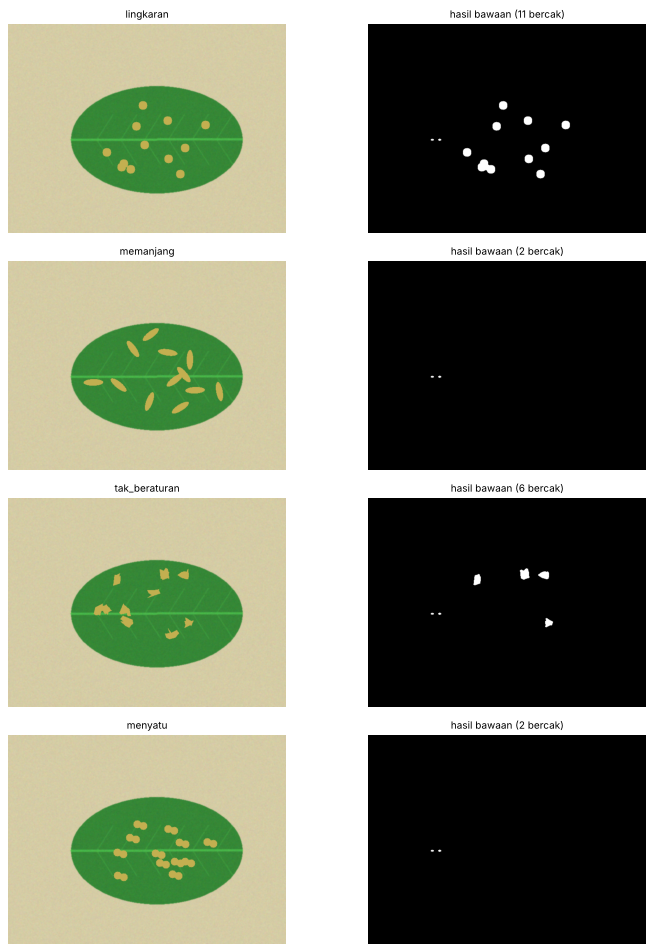

waktu analisis_daun: 6.1 ms/citra | praproses: 8.1 ms/citra


In [17]:
# P5.5: uji bentuk bercak tidak beraturan (sintetis) pada daun sehat teh_011
img, md, mb = muat("teh_011.png"); pra_ = praproses(img, PARAM)
rng = np.random.default_rng(7)
ys, xs = np.where(cv2.erode(md, np.ones((41, 41), np.uint8)) > 0)
def tempel(bentuk, n=12):
    out = pra_.copy(); acu = np.zeros(md.shape, np.uint8)
    for _ in range(n):
        i = rng.integers(len(xs)); cx, cy = int(xs[i]), int(ys[i])
        m = np.zeros(md.shape, np.uint8)
        if bentuk == "memanjang":     # elips rasio 3:1
            cv2.ellipse(m, (cx, cy), (22, 7), float(rng.uniform(0, 180)), 0, 360, 255, -1)
        elif bentuk == "tak_beraturan":   # poligon acak berlekuk
            t = np.sort(rng.uniform(0, 2 * np.pi, 9)); r = rng.uniform(5, 18, 9)
            pts = np.stack([cx + r * np.cos(t), cy + r * np.sin(t)], 1).astype(np.int32); cv2.fillPoly(m, [pts], 255)
        elif bentuk == "menyatu":     # dua lingkaran bersentuhan
            cv2.circle(m, (cx, cy), 9, 255, -1); cv2.circle(m, (cx + 14, cy + 4), 9, 255, -1)
        else:                         # lingkaran (seperti data sintetis)
            cv2.circle(m, (cx, cy), 10, 255, -1)
        out[m > 0] = (80, 175, 195); acu |= m
    return out, acu
baris = []; panel = []; judul = []
for bentuk in ["lingkaran", "memanjang", "tak_beraturan", "menyatu"]:
    im, acu = tempel(bentuk)
    for nm, pb in [("aturan bawaan", {}), ("tanpa filter bentuk", {"bulat_min": 0.0, "rasio_maks": 99})]:
        h = bercak.analisis_daun(im, pb)
        baris.append([bentuk, nm, h["jumlah_bercak"], round(100 * ((h["mask_bercak"] > 0) & (acu > 0)).sum() / (acu > 0).sum(), 1), round(iou(h["mask_bercak"], acu), 3)])
        if nm == "aturan bawaan": panel += [im, h["mask_bercak"]]; judul += [f"{bentuk}", f"hasil bawaan ({h['jumlah_bercak']} bercak)"]
print(pd.DataFrame(baris, columns=["bentuk", "aturan", "jumlah_terdeteksi (acuan 12)", "% luas tertangkap", "IoU"]))
tampil(panel, judul, baris=4, ukuran=(10, 12)); plt.savefig("../hasil/p6_uji_bentuk.png", bbox_inches="tight"); plt.show()
# waktu proses
t = []
for n in label.nama_file[:30]:
    t0 = time.perf_counter(); bercak.analisis_daun(PRA[n]); t.append(1000 * (time.perf_counter() - t0))
tp = []
for n in label.nama_file[:30]:
    t0 = time.perf_counter(); praproses(cache[n][0][0], PARAM); tp.append(1000 * (time.perf_counter() - t0))
print("waktu analisis_daun: %.1f ms/citra | praproses: %.1f ms/citra" % (np.mean(t), np.mean(tp)))

In [18]:
# Langkah 5.5 Checkpoint (terminal): git add . && git commit -m "P6: morfologi dan bercak.py"
# git tag v0.3-morfologi && git push && git push --tags
print('Tag v0.3-morfologi dibuat dari terminal.')

Tag v0.3-morfologi dibuat dari terminal.
